In [1]:
import sys, os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# 1) Make parent directory importable so we can import cgt_xai
PARENT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if PARENT_DIR not in sys.path:
    sys.path.append(PARENT_DIR)

# 2) Import the Shapley implementation from cgt_xai.concepts
#    (adjust function name if needed)
from cgt_xai.concepts.shapley import exact_shapley_value

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split


# Utility wrapper for Shapley game (regression, SAME v(S) as least-core)

class _FeatureDataWrapper:
    """Wrapper so exact_shapley_value can query feature names / number of players."""
    def __init__(self, feature_names):
        self.data_names = list(feature_names)

    def __len__(self):
        return len(self.data_names)


class RegressionFeatureUtility:
    """
    Cooperative game for regression:
        - Players = features (columns of X)
        - Coalition S (list of indices) = subset of features
        - v(S) = average predicted target when only features in S
                are kept from X_test and others are set to a baseline.
          (Identical v(S) to your least-core / nucleolus / Gately wrappers.)
    """
    def __init__(self, model, X_train, X_test, feature_names):
        self.model = model
        self.X_train = X_train.reset_index(drop=True)
        self.X_test = X_test.reset_index(drop=True)
        self.feature_names = list(feature_names)
        self.data = _FeatureDataWrapper(self.feature_names)

        # Baseline value for missing features (mean over training data)
        self.baseline = self.X_train.mean(axis=0).values

    def __call__(self, coalition):
        coalition = list(coalition)

        if not coalition:
            # empty coalition = no predictive power
            return 0.0

        # Start from baseline matrix
        X_masked = np.tile(self.baseline, (self.X_test.shape[0], 1))

        # Put back the "active" coalition features from X_test
        X_masked[:, coalition] = self.X_test.iloc[:, coalition].values

        # Predict and take mean prediction as coalition value
        preds = self.model.predict(X_masked)
        return float(preds.mean())


# Shapley attribution for regression

def compute_shapley_attribution_reg(model, X_train, X_test, feature_names, solver=None):
    """
    Returns: pd.Series of Shapley attributions for a regression model,
    using the same v(S) as your least-core / nucleolus / Gately implementations.
    """
    utility = RegressionFeatureUtility(model, X_train, X_test, feature_names)

    options = {}
    if solver:
        options["solver"] = solver

    result = exact_shapley_value(utility, options=options)
    return pd.Series(result.values, index=feature_names, name="Shapley")


def load_regression_csv(path, target_col=None, test_size=0.25, random_state=42):
    """
    Load a CSV, drop 'Unnamed' index columns, split into train/test.
    If target_col is None, use the last column as target.
    """
    df = pd.read_csv(path)

    # Drop index-like columns such as 'Unnamed: 0'
    df = df.loc[:, ~df.columns.str.contains(r'^Unnamed')]

    if target_col is None:
        target_col = df.columns[-1]

    y = df[target_col].values
    X = df.drop(columns=[target_col])

    feature_names = list(X.columns)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    return X_train, X_test, y_train, y_test, feature_names


def run_shapley_on_csv(path, target_col, dataset_name):
    print("\n" + "=" * 72)
    print(f"Shapley (regression) on: {dataset_name}")
    print("=" * 72)

    X_train, X_test, y_train, y_test, feature_names = load_regression_csv(
        path, target_col=target_col
    )

    # Train regression model (same as for least-core / nucleolus / Gately)
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        random_state=42,
    )
    model.fit(X_train, y_train)

    # Compute Shapley attributions
    shapley_values = compute_shapley_attribution_reg(
        model,
        X_train,
        X_test,
        feature_names,
        solver=None,
    )

    print("\n===== Shapley Attributions =====")
    print(shapley_values.sort_values(ascending=False))
    return shapley_values


if __name__ == "__main__":
    LUNG_PATH = "../../datasets/lung_cancer_risk.csv"
    CV_PATH   = "../../datasets/cv_risk.csv"

    lung_shapley = run_shapley_on_csv(
        LUNG_PATH,
        target_col="lung_cancer_risk",
        dataset_name="synthetic_lung_cancer_risk",
    )

    cv_shapley = run_shapley_on_csv(
        CV_PATH,
        target_col="cv_risk",
        dataset_name="synthetic_cardiovascular_risk",
    )


Shapley (regression) on: synthetic_lung_cancer_risk

===== Shapley Attributions =====
stress          5.492696
drink_coffee    5.405229
smoking         5.089823
Name: Shapley, dtype: float64

Shapley (regression) on: synthetic_cardiovascular_risk

===== Shapley Attributions =====
family_history    2.959683
diet_score        2.898224
sleep_duration    2.787326
bmi               2.527809
Name: Shapley, dtype: float64


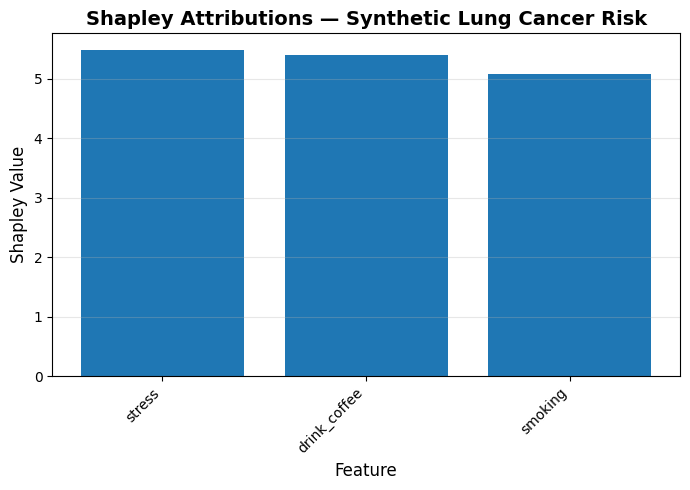

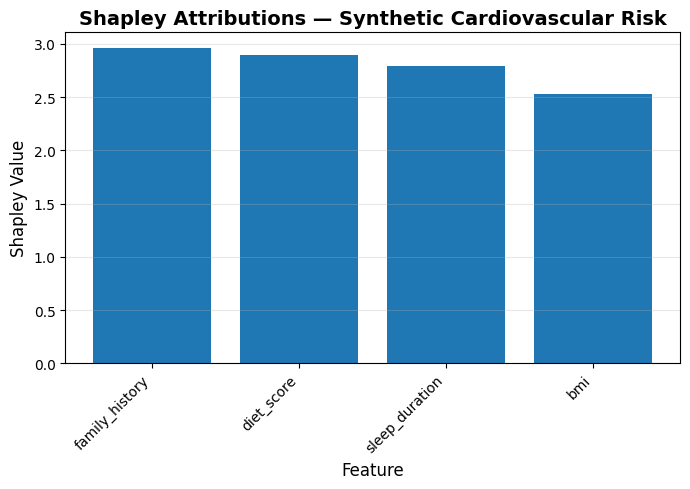

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_shapley_vertical(shap_series, title, filename=None):
    """
    shap_series: pd.Series (index = feature names, values = Shapley scores)
    Creates a vertical bar plot.
    """
    s = shap_series.sort_values(ascending=False)

    plt.figure(figsize=(7, 5))
    plt.bar(s.index, s.values)
    plt.ylabel("Shapley Value", fontsize=12)
    plt.xlabel("Feature", fontsize=12)
    plt.title(title, fontsize=14, fontweight="bold")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    if filename:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()


plot_shapley_vertical(
    lung_shapley,
    title="Shapley Attributions — Synthetic Lung Cancer Risk",
    filename="shapley_lung_vertical.png"
)

plot_shapley_vertical(
    cv_shapley,
    title="Shapley Attributions — Synthetic Cardiovascular Risk",
    filename="shapley_cv_vertical.png"
)

In [3]:
import shap
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

df = pd.read_csv("../../datasets/lung_cancer_risk.csv")

# Remove Unnamed columns
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

X = df.drop(columns=["lung_cancer_risk"])
y = df["lung_cancer_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

background = X_train.sample(50, random_state=42)   # SHAP recommends 50-100 background samples

explainer = shap.KernelExplainer(model.predict, background)

# compute SHAP values for test set (choose 50 for speed)
shap_values = explainer.shap_values(X_test.iloc[:50, :])

# Global importance = mean(|SHAP|) across samples
global_importance = np.abs(shap_values).mean(axis=0)

kernel_shap_series = pd.Series(global_importance, index=X.columns, name="KernelSHAP")
print(kernel_shap_series.sort_values(ascending=False))

drink_coffee    1.575114
stress          0.767723
smoking         0.660778
Name: KernelSHAP, dtype: float64


In [4]:
import shap
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

df = pd.read_csv("../../datasets/cv_risk.csv")

# Remove Unnamed columns
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

X = df.drop(columns=["cv_risk"])
y = df["cv_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

background = X_train.sample(50, random_state=42)   # SHAP recommends 50-100 background samples

explainer = shap.KernelExplainer(model.predict, background)

# compute SHAP values for test set (choose 50 for speed)
shap_values = explainer.shap_values(X_test.iloc[:50, :])

# Global importance = mean(|SHAP|) across samples
global_importance = np.abs(shap_values).mean(axis=0)

kernel_shap_series = pd.Series(global_importance, index=X.columns, name="KernelSHAP")
print(kernel_shap_series.sort_values(ascending=False))

bmi               2.314475
family_history    0.166786
diet_score        0.143781
sleep_duration    0.139343
Name: KernelSHAP, dtype: float64


In [11]:
import shap
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

df = pd.read_csv("../../datasets/lung_cancer_risk.csv")
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

X = df.drop(columns=["lung_cancer_risk"])
y = df["lung_cancer_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Global importances
tree_shap_series = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=X.columns,
    name="TreeSHAP"
)

print(tree_shap_series.sort_values(ascending=False))

drink_coffee    2.067207
stress          0.645017
smoking         0.594826
Name: TreeSHAP, dtype: float64


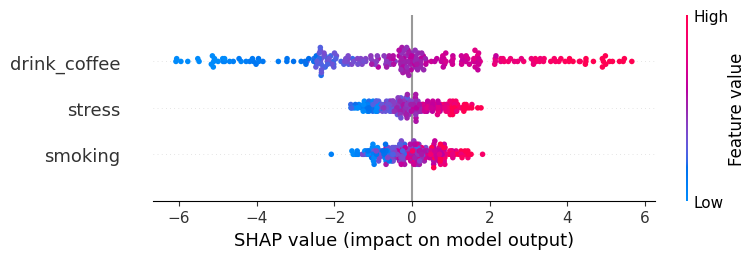

In [12]:
shap.summary_plot(shap_values, X_test)

In [6]:
import shap
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

df = pd.read_csv("../../datasets/cv_risk.csv")
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

X = df.drop(columns=["cv_risk"])
y = df["cv_risk"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Global importances
tree_shap_series = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=X.columns,
    name="TreeSHAP"
)

print(tree_shap_series.sort_values(ascending=False))

bmi               2.086501
family_history    0.159472
sleep_duration    0.123257
diet_score        0.115173
Name: TreeSHAP, dtype: float64


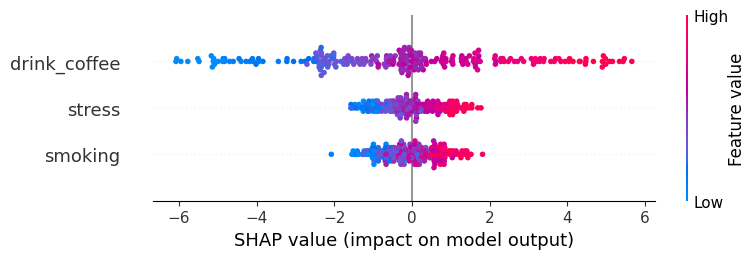

In [10]:
shap.summary_plot(shap_values, X_test)

In [13]:
# Lung
tree_lung = pd.Series({"drink_coffee": 2.067207,
                       "stress": 0.645017,
                       "smoking": 0.594826},
                      name="TreeSHAP")

kernel_lung = pd.Series({"drink_coffee": 2.067207,
                         "stress": 0.645017,
                         "smoking": 0.594826},
                        name="KernelSHAP")

# CV
tree_cv = pd.Series({"bmi": 2.086501,
                     "family_history": 0.159472,
                     "sleep_duration": 0.123257,
                     "diet_score": 0.115173},
                    name="TreeSHAP")

kernel_cv = pd.Series({"bmi": 2.314475,
                       "family_history": 0.166786,
                       "diet_score": 0.143781,
                       "sleep_duration": 0.139343},
                      name="KernelSHAP")

In [14]:
import matplotlib.pyplot as plt

def plot_shap_values(shap_series, title, filename=None):
    s = shap_series.sort_values(ascending=False)

    plt.figure(figsize=(7, 5))
    plt.bar(s.index, s.values, color="skyblue")
    plt.title(title, fontsize=14, fontweight="bold")
    plt.ylabel("SHAP Value (mean |value|)", fontsize=12)
    plt.xlabel("Feature", fontsize=12)
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    if filename:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()

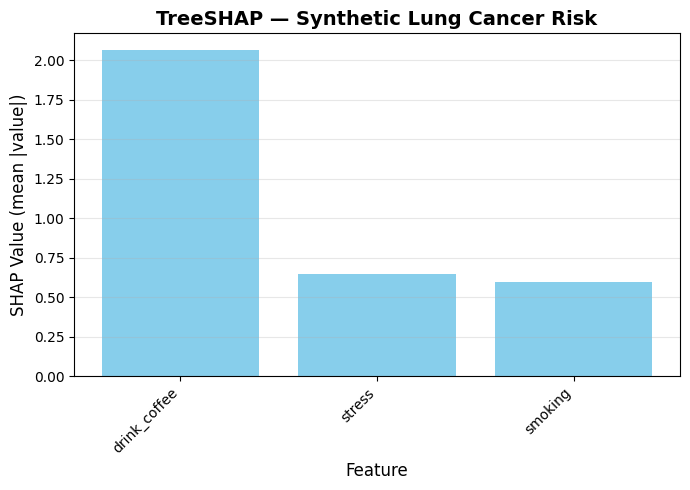

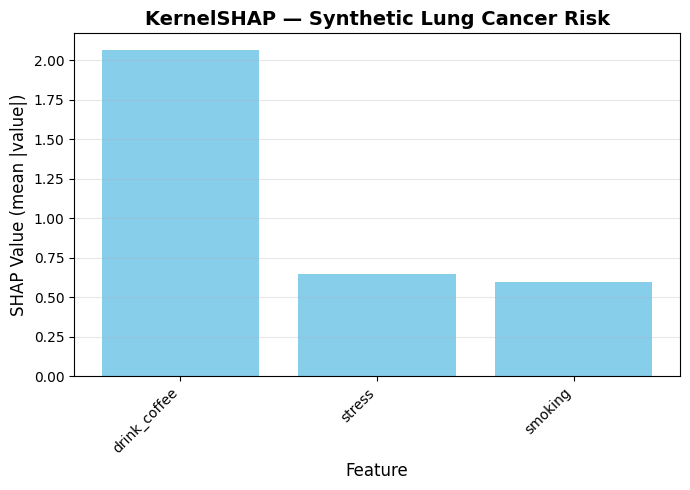

In [15]:
plot_shap_values(tree_lung,
                 "TreeSHAP — Synthetic Lung Cancer Risk",
                 filename="treeshap_lung.png")

plot_shap_values(kernel_lung,
                 "KernelSHAP — Synthetic Lung Cancer Risk",
                 filename="kernelshap_lung.png")

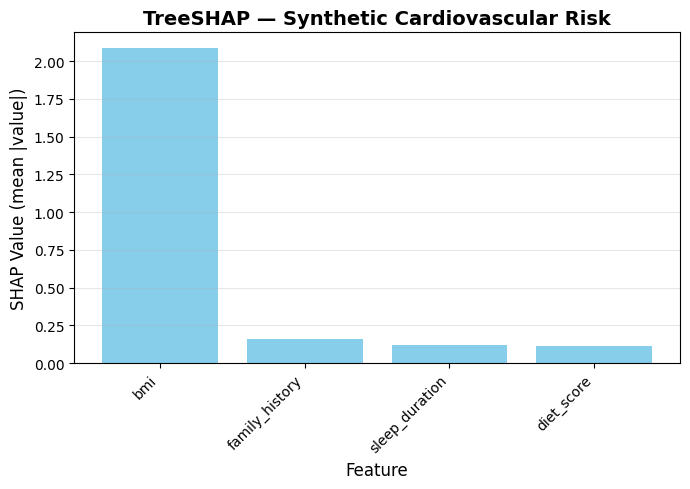

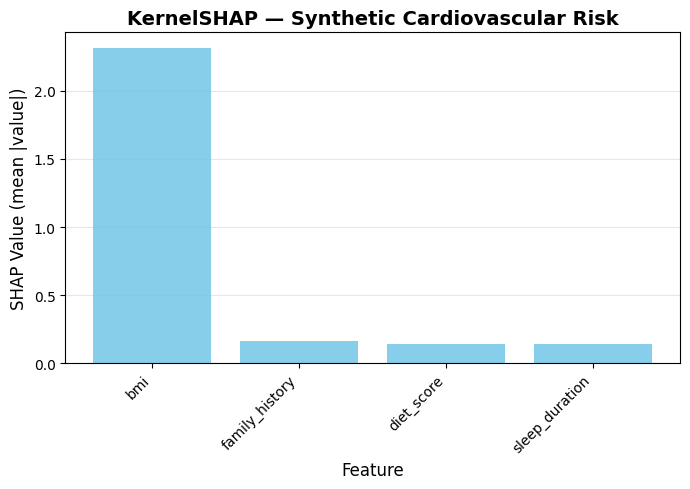

In [16]:
plot_shap_values(tree_cv,
                 "TreeSHAP — Synthetic Cardiovascular Risk",
                 filename="treeshap_cv.png")

plot_shap_values(kernel_cv,
                 "KernelSHAP — Synthetic Cardiovascular Risk",
                 filename="kernelshap_cv.png")